In [ ]:
from sklearn.datasets import make_blobs, make_circles
from sklearn.svm import SVC
import matplotlib.pyplot as plt
import numpy as np
from mlxtend.plotting import plot_decision_regions
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

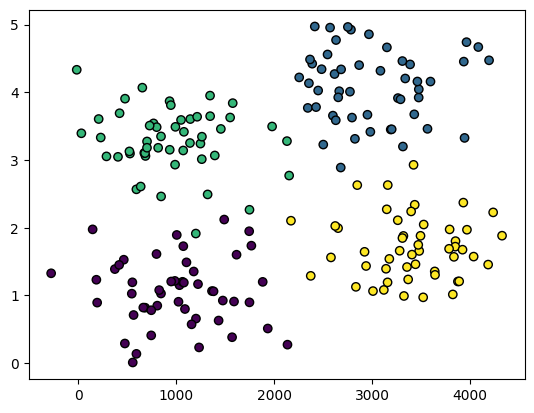

In [ ]:
blob_centers = ([1, 1], [3, 4], [1, 3.3], [3.5, 1.8])
X, y = make_blobs(n_samples=200,
                          centers=blob_centers,
                          cluster_std=0.5,
                          random_state=0)

X[:, 0] *= 1000

plt.scatter(X[:, 0], X[:, 1], c=y,  edgecolors='black',linewidth=1)

Создайте однослойный перцептрон с 1, 2, 10 и 100 нейронами. Сравние их точность и сделайте вывод о достаточном количестве нейронов.

In [ ]:
clf1 = MLPClassifier(hidden_layer_sizes=(1,),
                    random_state=1).fit(X, y)

In [ ]:
for i in range(len(clf1.coefs_)):
    number_neurons_in_layer = clf1.coefs_[i].shape[1]
    for j in range(number_neurons_in_layer):
        weights = clf1.coefs_[i][:,j]
        print(i, j, weights, end=", ")
        print()
    print()

0 0 [-0.16221846  0.55069073], 

1 0 [-0.50730545], 
1 1 [-0.8548355], 
1 2 [-0.81670486], 
1 3 [-0.76639623], 



In [ ]:
confusion_matrix(y, clf1.predict(X))

array([[ 1,  0, 49,  0],
       [ 0,  0, 50,  0],
       [ 1,  0, 49,  0],
       [ 0,  0, 50,  0]])

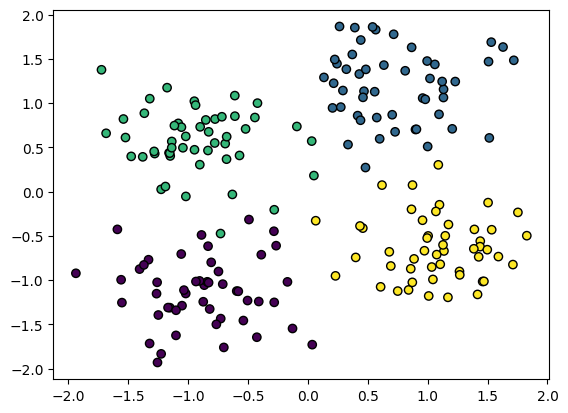

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y,  edgecolors='black',linewidth=1)

In [ ]:
clf1_1 = MLPClassifier(hidden_layer_sizes=(1,), max_iter=15_000, verbose=True).fit(X_scaled, y)

Iteration 1, loss = 1.67381559
Iteration 2, loss = 1.67218514
Iteration 3, loss = 1.67055975
Iteration 4, loss = 1.66893951
Iteration 5, loss = 1.66732449
Iteration 6, loss = 1.66571478
Iteration 7, loss = 1.66411047
Iteration 8, loss = 1.66251163
Iteration 9, loss = 1.66091834
Iteration 10, loss = 1.65933067
Iteration 11, loss = 1.65774870
Iteration 12, loss = 1.65617249
Iteration 13, loss = 1.65460212
Iteration 14, loss = 1.65303705
Iteration 15, loss = 1.65147489
Iteration 16, loss = 1.64991857
Iteration 17, loss = 1.64836819
Iteration 18, loss = 1.64682383
Iteration 19, loss = 1.64528555
Iteration 20, loss = 1.64375342
Iteration 21, loss = 1.64222749
Iteration 22, loss = 1.64070391
Iteration 23, loss = 1.63918573
Iteration 24, loss = 1.63767364
Iteration 25, loss = 1.63616772
Iteration 26, loss = 1.63466737
Iteration 27, loss = 1.63316850
Iteration 28, loss = 1.63167565
Iteration 29, loss = 1.63018894
Iteration 30, loss = 1.62870843
Iteration 31, loss = 1.62723305
Iteration 32, los

In [ ]:
confusion_matrix(y, clf1_1.predict(X_scaled))

array([[ 8,  0, 42,  0],
       [ 0, 26,  0, 24],
       [ 7,  0, 43,  0],
       [ 1,  9,  0, 40]])

In [ ]:
accuracy = accuracy_score(y, clf1_1.predict(X))
print(accuracy)

0.255


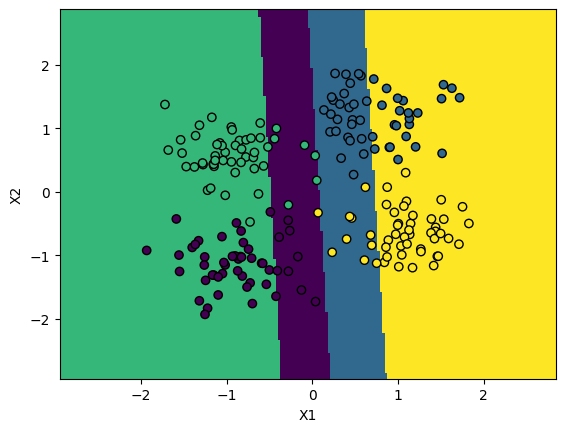

In [ ]:
X0 = np.linspace(X_scaled[:, 0].min()-1,X_scaled[:, 0].max()+1, X_scaled.shape[0])
X1 = np.linspace(X_scaled[:, 1].min()-1,X_scaled[:, 1].max()+1, X_scaled.shape[0])
X0_grid, X1_grid = np.meshgrid(X0, X1)

y_predict = clf1_1.predict(np.c_[X0_grid.ravel(),X1_grid.ravel()]).reshape(X0_grid.shape)
plt.pcolormesh(X0_grid, X1_grid, y_predict)

plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y,  edgecolors='black',linewidth=1)
plt.xlabel('X1')
plt.ylabel('X2')
plt.show()

In [ ]:
clf2 = MLPClassifier(hidden_layer_sizes=(2,),
                    random_state=1).fit(X, y)

/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


In [ ]:
for i in range(len(clf2.coefs_)):
    number_neurons_in_layer = clf2.coefs_[i].shape[1]
    for j in range(number_neurons_in_layer):
        weights = clf2.coefs_[i][:,j]
        print(i, j, weights, end=", ")
        print()
    print()

0 0 [-0.02639642 -1.40131517], 
0 1 [ 0.36864028 -0.66136826], 

1 0 [-0.4896679   0.02289867], 
1 1 [-0.63474453  0.55495194], 
1 2 [-0.58217999 -0.40667075], 
1 3 [-0.05982738  0.57173952], 



In [ ]:
confusion_matrix(y, clf2.predict(X))

array([[ 0,  0,  0, 50],
       [ 0,  0,  0, 50],
       [ 0,  2,  0, 48],
       [ 0,  0,  0, 50]])

In [ ]:
clf2_2 = MLPClassifier(hidden_layer_sizes=(2,), max_iter=9_000, verbose=1).fit(X, y)

Iteration 1, loss = 1.65784678
Iteration 2, loss = 1.65743189
Iteration 3, loss = 1.65701802
Iteration 4, loss = 1.65660521
Iteration 5, loss = 1.65619345
Iteration 6, loss = 1.65578277
Iteration 7, loss = 1.65537318
Iteration 8, loss = 1.65496470
Iteration 9, loss = 1.65455735
Iteration 10, loss = 1.65415113
Iteration 11, loss = 1.65374606
Iteration 12, loss = 1.65334216
Iteration 13, loss = 1.65293943
Iteration 14, loss = 1.65253789
Iteration 15, loss = 1.65213756
Iteration 16, loss = 1.65173844
Iteration 17, loss = 1.65134054
Iteration 18, loss = 1.65094388
Iteration 19, loss = 1.65054846
Iteration 20, loss = 1.65015429
Iteration 21, loss = 1.64976139
Iteration 22, loss = 1.64936975
Iteration 23, loss = 1.64897939
Iteration 24, loss = 1.64859032
Iteration 25, loss = 1.64820254
Iteration 26, loss = 1.64781606
Iteration 27, loss = 1.64743087
Iteration 28, loss = 1.64704700
Iteration 29, loss = 1.64666444
Iteration 30, loss = 1.64628319
Iteration 31, loss = 1.64590327
Iteration 32, los

In [ ]:
confusion_matrix(y, clf2_2.predict(X))

array([[ 0, 49,  1,  0],
       [ 0, 50,  0,  0],
       [ 0, 48,  2,  0],
       [ 0, 50,  0,  0]])

In [ ]:
accuracy = accuracy_score(y, clf2_2.predict(X))
print(accuracy)

0.26


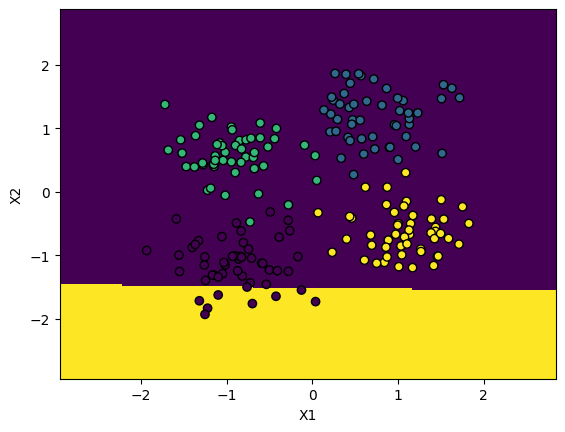

In [ ]:
X0 = np.linspace(X_scaled[:, 0].min()-1,X_scaled[:, 0].max()+1, X_scaled.shape[0])
X1 = np.linspace(X_scaled[:, 1].min()-1,X_scaled[:, 1].max()+1, X_scaled.shape[0])
X0_grid, X1_grid = np.meshgrid(X0, X1)

y_predict = clf2.predict(np.c_[X0_grid.ravel(),X1_grid.ravel()]).reshape(X0_grid.shape)
plt.pcolormesh(X0_grid, X1_grid, y_predict)

plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y,  edgecolors='black',linewidth=1)
plt.xlabel('X1')
plt.ylabel('X2')
plt.show()

In [ ]:
clf10 = MLPClassifier(hidden_layer_sizes=(10,),
                    random_state=1).fit(X, y)

In [ ]:
confusion_matrix(y, clf10.predict(X))

array([[ 4,  0,  0, 46],
       [ 0,  0,  0, 50],
       [ 1,  1,  0, 48],
       [ 0,  0,  0, 50]])

In [ ]:
clf10_10 = MLPClassifier(hidden_layer_sizes=(10,), max_iter=10_000, verbose=1).fit(X, y)

Iteration 1, loss = 26.75961385
Iteration 2, loss = 26.75865360
Iteration 3, loss = 26.75771778
Iteration 4, loss = 26.75680657
Iteration 5, loss = 26.75591993
Iteration 6, loss = 26.75505757
Iteration 7, loss = 26.75421896
Iteration 8, loss = 26.75340332
Iteration 9, loss = 26.74228538
Iteration 10, loss = 26.72637956
Iteration 11, loss = 26.71050656
Iteration 12, loss = 26.69466552
Iteration 13, loss = 26.67885557
Iteration 14, loss = 26.66307586
Iteration 15, loss = 26.64545127
Iteration 16, loss = 26.62609784
Iteration 17, loss = 26.60677446
Iteration 18, loss = 26.58748029
Iteration 19, loss = 26.56821459
Iteration 20, loss = 26.54897759
Iteration 21, loss = 26.52977892
Iteration 22, loss = 26.51072371
Iteration 23, loss = 26.49274399
Iteration 24, loss = 26.47938046
Iteration 25, loss = 26.47066597
Iteration 26, loss = 26.46161510
Iteration 27, loss = 26.44961564
Iteration 28, loss = 26.43763513
Iteration 29, loss = 26.42565823
Iteration 30, loss = 26.41368344
Iteration 31, loss 

In [ ]:
confusion_matrix(y, clf10_10.predict(X))

array([[ 1,  0,  8, 41],
       [ 0,  0,  0, 50],
       [ 1,  0, 35, 14],
       [ 0,  0,  0, 50]])

In [ ]:
accuracy = accuracy_score(y, clf10_10.predict(X))
print(accuracy)

0.43


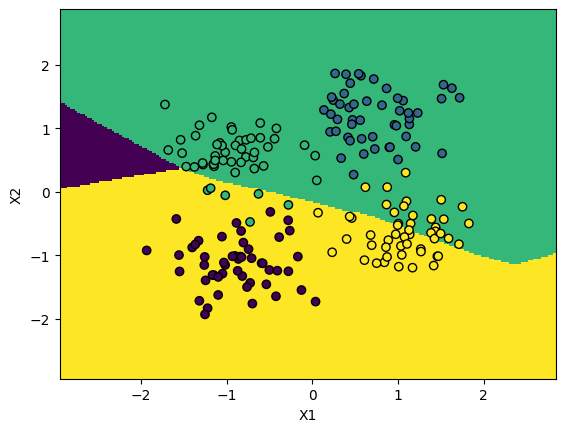

In [ ]:
X0 = np.linspace(X_scaled[:, 0].min()-1,X_scaled[:, 0].max()+1, X_scaled.shape[0])
X1 = np.linspace(X_scaled[:, 1].min()-1,X_scaled[:, 1].max()+1, X_scaled.shape[0])
X0_grid, X1_grid = np.meshgrid(X0, X1)

y_predict = clf10_10.predict(np.c_[X0_grid.ravel(),X1_grid.ravel()]).reshape(X0_grid.shape)
plt.pcolormesh(X0_grid, X1_grid, y_predict)

plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y,  edgecolors='black',linewidth=1)
plt.xlabel('X1')
plt.ylabel('X2')
plt.show()

In [ ]:
clf100 = MLPClassifier(hidden_layer_sizes=(100,),
                    random_state=1).fit(X, y)

In [ ]:
confusion_matrix(y, clf100.predict(X))

array([[ 4,  0,  0, 46],
       [ 0,  0,  0, 50],
       [ 1,  1,  0, 48],
       [ 0,  0,  0, 50]])

In [ ]:
clf100_100 = MLPClassifier(hidden_layer_sizes=(100,), max_iter=500, verbose=True).fit(X, y)

Iteration 1, loss = 26.83208162
Iteration 2, loss = 26.80842896
Iteration 3, loss = 26.76067331
Iteration 4, loss = 26.71391873
Iteration 5, loss = 19.18373214
Iteration 6, loss = 21.93617680
Iteration 7, loss = 24.04458667
Iteration 8, loss = 24.72993342
Iteration 9, loss = 24.95222427
Iteration 10, loss = 24.96929316
Iteration 11, loss = 24.82185837
Iteration 12, loss = 24.47607537
Iteration 13, loss = 23.77898038
Iteration 14, loss = 22.46735100
Iteration 15, loss = 14.22662174
Iteration 16, loss = 21.93841175
Iteration 17, loss = 21.71580587
Iteration 18, loss = 20.30372930
Iteration 19, loss = 17.95828338
Iteration 20, loss = 18.90135896
Iteration 21, loss = 20.28472408
Iteration 22, loss = 18.36650876
Iteration 23, loss = 15.95883817
Iteration 24, loss = 16.16965371
Iteration 25, loss = 12.64179180
Iteration 26, loss = 6.72651720
Iteration 27, loss = 12.24569898
Iteration 28, loss = 14.66338297
Iteration 29, loss = 14.35257590
Iteration 30, loss = 11.57051746
Iteration 31, loss =

In [ ]:
confusion_matrix(y, clf100_100.predict(X))

array([[ 1, 49,  0,  0],
       [ 0, 50,  0,  0],
       [ 0, 49,  1,  0],
       [ 0, 50,  0,  0]])

In [ ]:
accuracy = accuracy_score(y, clf100_100.predict(X))
print(accuracy)

0.26


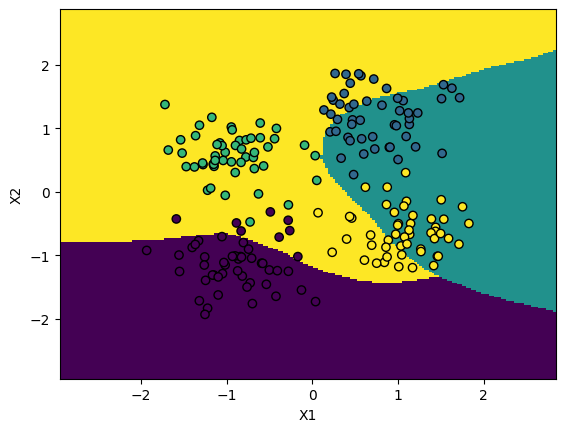

In [ ]:
X0 = np.linspace(X_scaled[:, 0].min()-1,X_scaled[:, 0].max()+1, X_scaled.shape[0])
X1 = np.linspace(X_scaled[:, 1].min()-1,X_scaled[:, 1].max()+1, X_scaled.shape[0])
X0_grid, X1_grid = np.meshgrid(X0, X1)

y_predict = clf100_100.predict(np.c_[X0_grid.ravel(),X1_grid.ravel()]).reshape(X0_grid.shape)
plt.pcolormesh(X0_grid, X1_grid, y_predict)

plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y,  edgecolors='black',linewidth=1)
plt.xlabel('X1')
plt.ylabel('X2')
plt.show()

Создайте и оцените модель с двумя, тремя и десятью скрытыми слоями с одинаковым количеством нейронов. Сравните их точность и сделайте вывод о достаточном количестве слоев.

In [ ]:
clf_1 = MLPClassifier(hidden_layer_sizes=(10,), max_iter=5000, verbose=True).fit(X, y)

Iteration 1, loss = 26.50446030
Iteration 2, loss = 26.48385166
Iteration 3, loss = 26.46330740
Iteration 4, loss = 26.44282966
Iteration 5, loss = 26.42242079
Iteration 6, loss = 26.40208413
Iteration 7, loss = 26.38183311
Iteration 8, loss = 26.36178845
Iteration 9, loss = 26.34302708
Iteration 10, loss = 26.32936272
Iteration 11, loss = 26.32026127
Iteration 12, loss = 26.31215418
Iteration 13, loss = 26.30421783
Iteration 14, loss = 26.29634981
Iteration 15, loss = 26.28853517
Iteration 16, loss = 26.28077041
Iteration 17, loss = 26.27048339
Iteration 18, loss = 26.25782498
Iteration 19, loss = 26.24524102
Iteration 20, loss = 26.23273145
Iteration 21, loss = 26.21663436
Iteration 22, loss = 26.19882349
Iteration 23, loss = 26.18111862
Iteration 24, loss = 26.16188937
Iteration 25, loss = 26.13782059
Iteration 26, loss = 26.10845068
Iteration 27, loss = 26.07925962
Iteration 28, loss = 26.05024807
Iteration 29, loss = 26.01668530
Iteration 30, loss = 25.96634077
Iteration 31, loss 

In [ ]:
confusion_matrix(y, clf_1.predict(X))

array([[ 3,  0,  0, 47],
       [ 0,  0,  0, 50],
       [10,  0,  1, 39],
       [ 0,  0,  0, 50]])

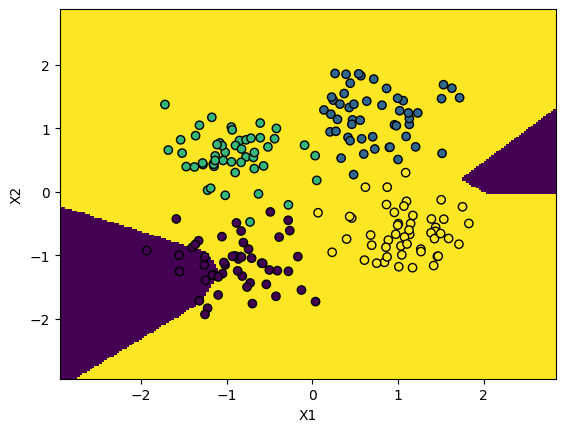

In [ ]:
X0 = np.linspace(X_scaled[:, 0].min()-1,X_scaled[:, 0].max()+1, X_scaled.shape[0])
X1 = np.linspace(X_scaled[:, 1].min()-1,X_scaled[:, 1].max()+1, X_scaled.shape[0])
X0_grid, X1_grid = np.meshgrid(X0, X1)

y_predict = clf_1.predict(np.c_[X0_grid.ravel(),X1_grid.ravel()]).reshape(X0_grid.shape)
plt.pcolormesh(X0_grid, X1_grid, y_predict)

plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y,  edgecolors='black',linewidth=1)
plt.xlabel('X1')
plt.ylabel('X2')
plt.show()

In [ ]:
clf_2 = MLPClassifier(hidden_layer_sizes=(10, 10), max_iter=3000, verbose=True).fit(X, y)

Iteration 1, loss = 25.22547227
Iteration 2, loss = 25.01423010
Iteration 3, loss = 24.76387331
Iteration 4, loss = 24.46711914
Iteration 5, loss = 24.11666587
Iteration 6, loss = 23.69717183
Iteration 7, loss = 23.18583828
Iteration 8, loss = 22.74867828
Iteration 9, loss = 22.33911066
Iteration 10, loss = 21.90135332
Iteration 11, loss = 21.45536606
Iteration 12, loss = 20.98039061
Iteration 13, loss = 20.48976829
Iteration 14, loss = 20.00697331
Iteration 15, loss = 19.52463230
Iteration 16, loss = 19.04800477
Iteration 17, loss = 18.57812917
Iteration 18, loss = 18.10960792
Iteration 19, loss = 17.65108027
Iteration 20, loss = 17.20746960
Iteration 21, loss = 16.83915246
Iteration 22, loss = 17.02899106
Iteration 23, loss = 17.16870641
Iteration 24, loss = 16.83935491
Iteration 25, loss = 16.25936544
Iteration 26, loss = 15.83153293
Iteration 27, loss = 15.47232379
Iteration 28, loss = 15.06180306
Iteration 29, loss = 14.59377955
Iteration 30, loss = 13.99813985
Iteration 31, loss 

In [ ]:
confusion_matrix(y, clf_2.predict(X))

array([[ 1, 49,  0,  0],
       [ 0, 50,  0,  0],
       [ 0, 49,  1,  0],
       [ 0, 50,  0,  0]])

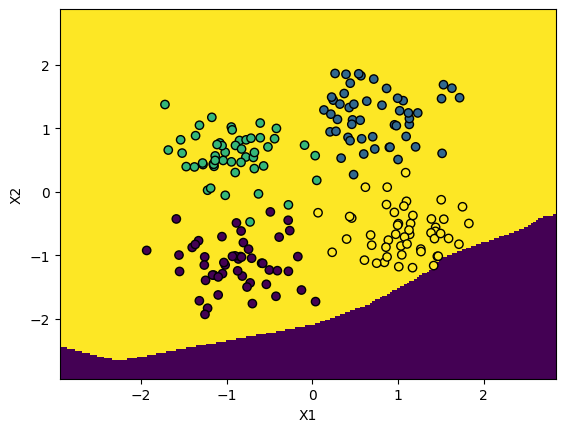

In [ ]:
X0 = np.linspace(X_scaled[:, 0].min()-1,X_scaled[:, 0].max()+1, X_scaled.shape[0])
X1 = np.linspace(X_scaled[:, 1].min()-1,X_scaled[:, 1].max()+1, X_scaled.shape[0])
X0_grid, X1_grid = np.meshgrid(X0, X1)

y_predict = clf_2.predict(np.c_[X0_grid.ravel(),X1_grid.ravel()]).reshape(X0_grid.shape)
plt.pcolormesh(X0_grid, X1_grid, y_predict)

plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y,  edgecolors='black',linewidth=1)
plt.xlabel('X1')
plt.ylabel('X2')
plt.show()